In [1]:
import numpy as np
import sympy as sm
import pandas as pd

import scipy as sp
from scipy.integrate import solve_ivp
import scipy.optimize as optimize

import matplotlib as mp
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import acf

import os
from tqdm import tqdm
import glob

In [2]:
params_df = pd.read_csv('../data/params_combos.csv')
params_df["R0"] = (params_df["Beta"] * 1000 / params_df["Alpha"]).round(2) #Calculate R0
params_df = params_df.sort_values("R0").reset_index(drop=True) #Sort df by R0

In [3]:
# Load trajectory files and map to params_df
data_dir = '../data/ctmc_trajectories' #Load data
csv_files = sorted(glob.glob(os.path.join(data_dir, '*.csv')))
param_to_file = {}
for file in csv_files:
    name = os.path.basename(file).replace('.csv', '').replace("alpha", "").replace("beta", "")
    parts = name.split("_")
    alpha = float(parts[0].replace("p", "."))
    beta = float(parts[1].replace("p", "."))
    param_to_file[(alpha, beta)] = file

In [4]:
# --- ODE Model Setup ---
def dydt(t, y, par):
    alpha, beta = np.abs(par)
    S, I, R, C = y
    dS = -beta * S * I
    dI = beta * S * I - alpha * I
    dR = alpha * I
    dC = beta * S * I
    return np.array([dS, dI, dR, dC])

def SolveModel(par, tspan, init_cond, t_eval):
    return solve_ivp(dydt, tspan, init_cond, t_eval=t_eval, args=(par,))

In [5]:
# Define initial conditions
N0 = 1000
I0 = 5
R0 = 0
C0 = 0
S0 = N0 - I0 - R0
init_cond = np.array([S0, I0, R0, C0])

#Define time variables
t_final=100
tspan = (1,t_final)
t_eval = np.arange(1, 101)
tdata = np.arange(0,t_final)

In [6]:
# --- CTMC Residual Collection ---
ctmc_residual_matrix = []
# Select the combination by value, not by position: the position depends on
# how ties in R0 are ordered when params_df is sorted.
row = params_df[(params_df["Alpha"] == 0.1) & (params_df["Beta"] == 0.0004)].iloc[0]
alpha, beta = row["Alpha"], row["Beta"]
par = (alpha, beta)
file = param_to_file[(alpha, beta)]
df = pd.read_csv(file)
soln = SolveModel(par, tspan, init_cond, t_eval)
I_ode = soln.y[1]
I_peak = np.max(I_ode)

for traj_id in df["trajectory"].unique():
    df_traj = df[df["trajectory"] == traj_id].sort_values("time")
    resids = []
    for i, row_t in df_traj.iterrows():
        t = int(row_t["time"])
        if t in t_eval:
            t_idx = t - 1
            i_ctmc = row_t["I"]
            i_ode_val = I_ode[t_idx]
            if i_ode_val >= 0.01 * I_peak and i_ctmc > 0:
                residual = (i_ctmc - i_ode_val) / i_ode_val
                resids.append(residual)
            else:
                resids.append(np.nan)
    ctmc_residual_matrix.append(resids)

ctmc_residual_matrix = np.array(ctmc_residual_matrix)
threshold = 0.01
valid_time_mask = np.mean(np.isnan(ctmc_residual_matrix), axis=0) < threshold

# Keep only columns (time points) where fewer than 1% of trajectories have NaN
ctmc_residual_matrix = ctmc_residual_matrix[:, valid_time_mask]

ctmc_residual_matrix = ctmc_residual_matrix[~np.isnan(ctmc_residual_matrix).any(axis=1)]

In [7]:
par

(np.float64(0.1), np.float64(0.0004))

In [8]:
np.shape(ctmc_residual_matrix)

(994, 72)

In [9]:
# --- Gaussian Noise Simulation and Residuals ---
sigma = 0.1
gauss_residual_matrix = []
for _ in range(1000):
    noise = np.random.normal(loc=0, scale=sigma, size=len(I_ode))
    I_sim = I_ode * (1 + noise)
    residuals = (I_sim - I_ode) / I_ode
    gauss_residual_matrix.append(residuals)
gauss_residual_matrix = np.array(gauss_residual_matrix)

In [10]:
# --- Mean ACF Computation ---
def compute_mean_acf_array(residual_matrix, nlags=40):
    acf_list = []
    for i in range(residual_matrix.shape[0]):
        res = residual_matrix[i]
        if np.count_nonzero(~np.isnan(res)) > nlags:
            acf_vals = acf(res, nlags=nlags, fft=False)
            acf_list.append(acf_vals)
    acf_array = np.array(acf_list)
    mean_acf = np.mean(acf_array, axis=0)
    std_acf = np.std(acf_array, axis=0)
    n_samples = len(acf_array)
    return mean_acf, std_acf, n_samples


mean_acf_ctmc, std_acf_ctmc, n_ctmc = compute_mean_acf_array(ctmc_residual_matrix)
mean_acf_gauss, std_acf_gauss, n_gauss = compute_mean_acf_array(gauss_residual_matrix)



In [11]:
mean_acf_ctmc

array([ 1.        ,  0.895885  ,  0.80615891,  0.72587641,  0.65150778,
        0.58317244,  0.51906917,  0.45816688,  0.40022429,  0.34475969,
        0.29319036,  0.2459143 ,  0.20126501,  0.16051976,  0.12327046,
        0.08924136,  0.05863081,  0.03126331,  0.00647861, -0.01616752,
       -0.03744249, -0.05695265, -0.07384804, -0.08885988, -0.10230072,
       -0.11441308, -0.12478466, -0.13386547, -0.14284019, -0.15039525,
       -0.15693386, -0.163269  , -0.16906375, -0.17406277, -0.17836772,
       -0.18234599, -0.18601424, -0.18884227, -0.19139357, -0.19304386,
       -0.19407763])

In [12]:
# Average ACF over first 100 trajectories only
mean_acf_ctmc, std_acf_ctmc, n_ctmc = compute_mean_acf_array(ctmc_residual_matrix[:100])
mean_acf_gauss, std_acf_gauss, n_gauss = compute_mean_acf_array(gauss_residual_matrix[:100])


In [13]:
ci_ctmc_upper = mean_acf_ctmc + 1.96 * (std_acf_ctmc / np.sqrt(n_ctmc))
ci_ctmc_lower = mean_acf_ctmc - 1.96 * (std_acf_ctmc / np.sqrt(n_ctmc))

ci_gauss_upper = mean_acf_gauss + 1.96 * (std_acf_gauss / np.sqrt(n_gauss))
ci_gauss_lower = mean_acf_gauss - 1.96 * (std_acf_gauss / np.sqrt(n_gauss))


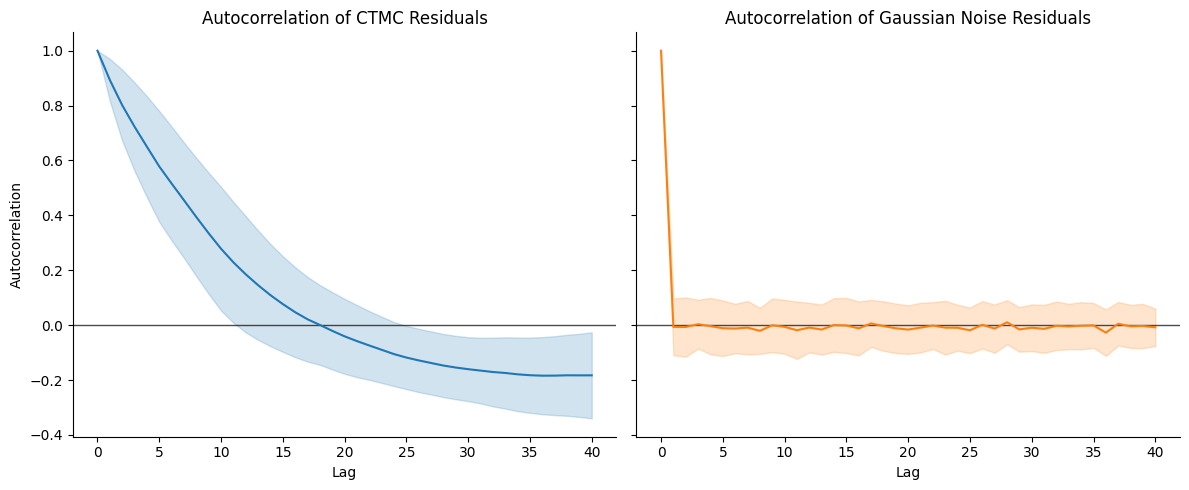

In [14]:
lags = np.arange(len(mean_acf_ctmc))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot for CTMC Residuals
axes[0].axhline(0, color="black", linewidth=1, alpha = 0.7)
axes[0].plot(lags, mean_acf_ctmc, color="tab:blue")
axes[0].fill_between(lags, mean_acf_ctmc - std_acf_ctmc, mean_acf_ctmc + std_acf_ctmc,
                     color="tab:blue", alpha=0.2)
axes[0].set_title("Autocorrelation of CTMC Residuals")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Plot for Gaussian Residuals
axes[1].axhline(0, color="black", linewidth=1, alpha = 0.7)
axes[1].plot(lags, mean_acf_gauss, color="tab:orange")
axes[1].fill_between(lags, mean_acf_gauss - std_acf_gauss, mean_acf_gauss + std_acf_gauss,
                     color="tab:orange", alpha=0.2)
axes[1].set_title("Autocorrelation of Gaussian Noise Residuals")
axes[1].set_xlabel("Lag")
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

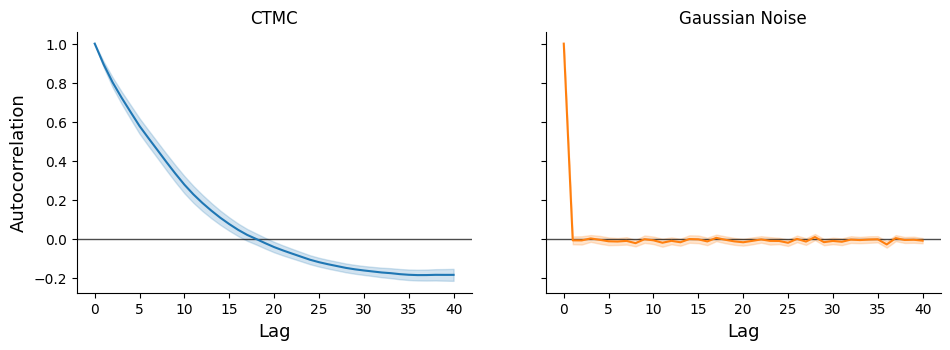

In [15]:
lags = np.arange(len(mean_acf_ctmc))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# CTMC Residuals
axes[0].axhline(0, color="black", linewidth=1, alpha=0.7)
axes[0].plot(lags, mean_acf_ctmc, color="tab:blue")
axes[0].fill_between(lags, ci_ctmc_lower, ci_ctmc_upper, color="tab:blue", alpha=0.2)
axes[0].set_title("CTMC")
axes[0].set_xlabel("Lag", fontsize=13)
axes[0].set_ylabel("Autocorrelation", fontsize=13)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Gaussian Residuals
axes[1].axhline(0, color="black", linewidth=1, alpha=0.7)
axes[1].plot(lags, mean_acf_gauss, color="tab:orange")
axes[1].fill_between(lags, ci_gauss_lower, ci_gauss_upper, color="tab:orange", alpha=0.2)
axes[1].set_title("Gaussian Noise")
axes[1].set_xlabel("Lag", fontsize=13)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout(pad=2.5, w_pad=5.0)
plt.show()

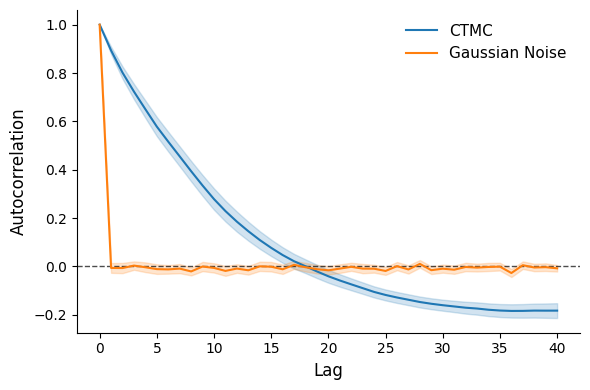

In [16]:
lags = np.arange(len(mean_acf_ctmc))
fig, ax = plt.subplots(figsize=(6, 4))

# CTMC Residuals
ax.axhline(0, color="black", linewidth=1, alpha=0.7, linestyle = '--')
ax.plot(lags, mean_acf_ctmc, color="tab:blue", label="CTMC")
ax.fill_between(lags, ci_ctmc_lower, ci_ctmc_upper, color="tab:blue", alpha=0.2)

# Gaussian Residuals
ax.plot(lags, mean_acf_gauss, color="tab:orange", label="Gaussian Noise")
ax.fill_between(lags, ci_gauss_lower, ci_gauss_upper, color="tab:orange", alpha=0.2)

# Axes labels & style
ax.set_xlabel("Lag", fontsize=12)
ax.set_ylabel("Autocorrelation", fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.show()
